# Task 1 — Iris Flower Classification

Predict Setosa, Versicolor, or Virginica from four measurements. Uses scikit-learn’s built-in Iris dataset; no download is needed. This notebook covers EDA, visualizations, three classifiers, evaluation, and feature importance.

In [11]:
# If needed: %pip install pandas numpy matplotlib seaborn scikit-learn
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, precision_recall_fscore_support
RANDOM_STATE=42; sns.set_theme(style='whitegrid')

## 1. Load and inspect data

In [12]:
iris=load_iris(as_frame=True); df=iris.frame.copy()
df['species']=df['target'].map(dict(enumerate(iris.target_names))); df=df.drop(columns='target')
features=iris.feature_names
print('Shape:',df.shape); display(df.head()); print(df.dtypes); print('Nulls:\n',df.isna().sum()); print('Duplicates:',df.duplicated().sum()); display(df[features].describe().T); print(df.species.value_counts())

Shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species               object
dtype: object
Nulls:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64
Duplicates: 1


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## 2. Exploratory visualizations

The pairplot shows pairwise feature separation. Petal length and petal width generally separate species more clearly than sepal measurements.

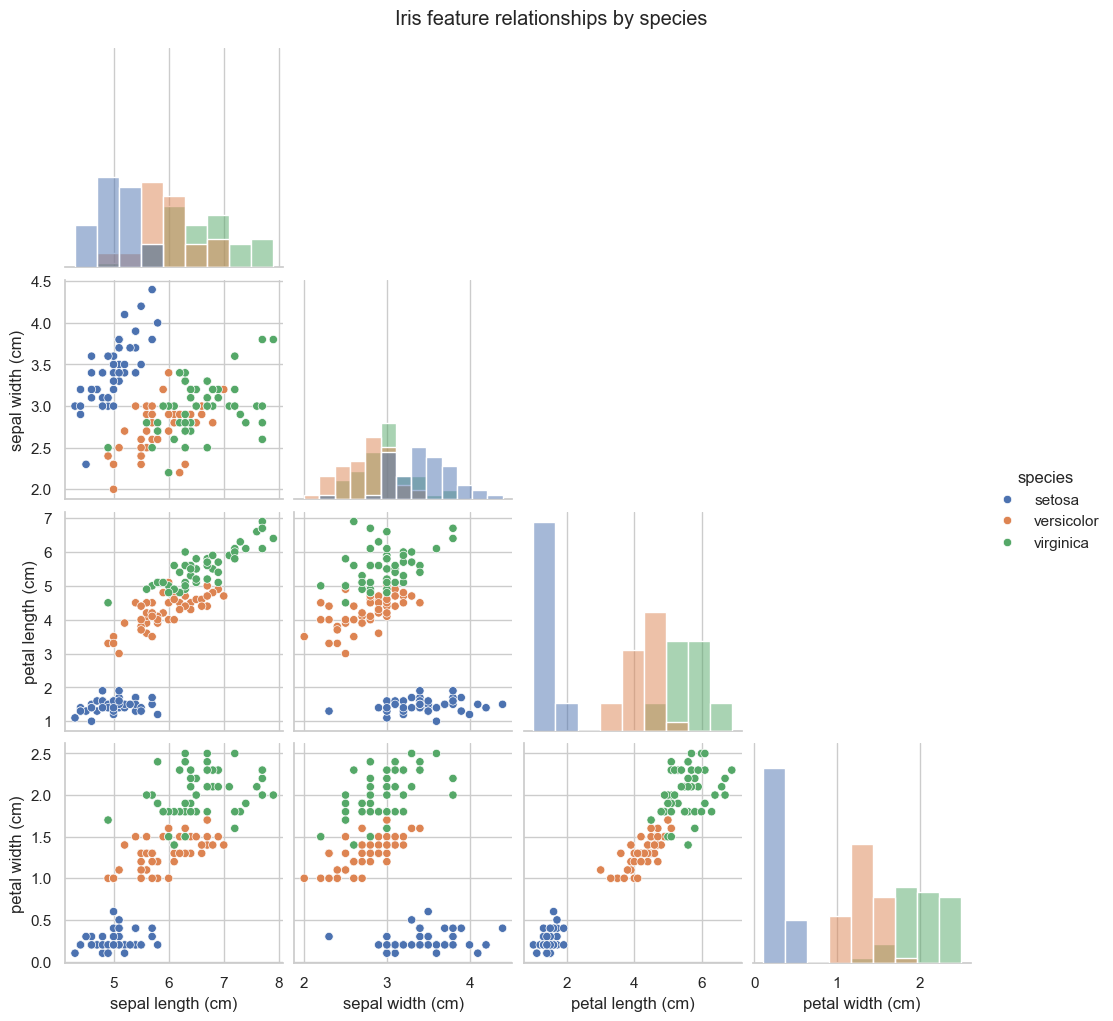

In [13]:
sns.pairplot(df,vars=features,hue='species',diag_kind='hist',corner=True); plt.suptitle('Iris feature relationships by species',y=1.02); plt.show()

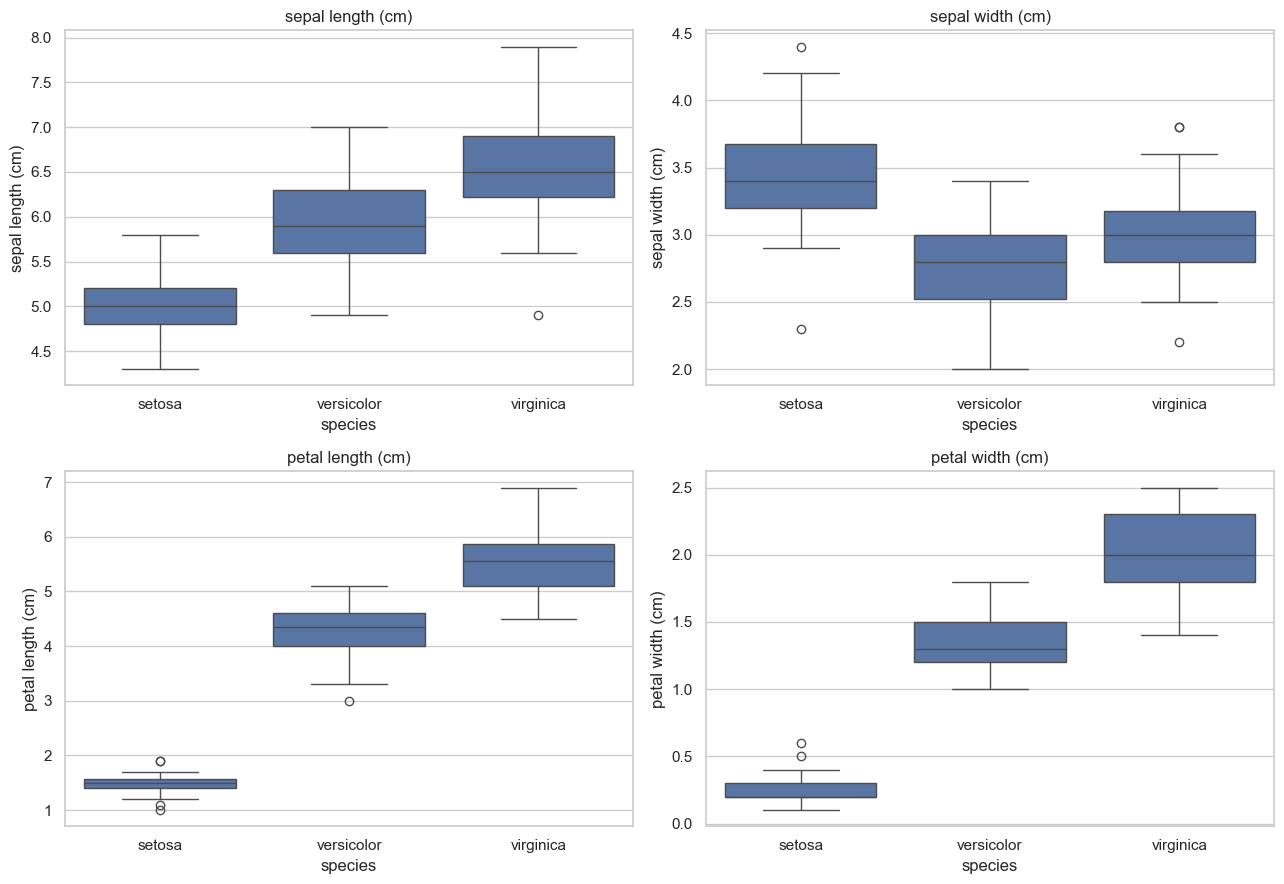

In [4]:
fig,axes=plt.subplots(2,2,figsize=(13,9))
for ax,f in zip(axes.flat,features): sns.boxplot(data=df,x='species',y=f,ax=ax); ax.set_title(f)
plt.tight_layout(); plt.show()

## 3. Feature selection discussion

Petal length and petal width are usually the most discriminative: Setosa is clearly separated, while Versicolor and Virginica overlap somewhat. Sepal features add information but are generally less distinctive alone. We retain all four features and inspect Random Forest importances as a supporting diagnostic.

In [5]:
X=df[features]; y=df.species
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=RANDOM_STATE,stratify=y)
print('Train/test:',X_train.shape,X_test.shape)

Train/test: (120, 4) (30, 4)


## 4. Train at least two classifiers

Scaling is fitted within pipelines to prevent leakage. Random Forest does not require scaling.

In [6]:
models={'Logistic Regression':Pipeline([('scale',StandardScaler()),('model',LogisticRegression(max_iter=1000,random_state=RANDOM_STATE))]),'K-Nearest Neighbours':Pipeline([('scale',StandardScaler()),('model',KNeighborsClassifier(n_neighbors=5))]),'Random Forest':RandomForestClassifier(n_estimators=300,random_state=RANDOM_STATE)}
fitted={}; rows=[]
for name,model in models.items():
 model.fit(X_train,y_train); pred=model.predict(X_test); fitted[name]=model
 rows.append({'Model':name,'Accuracy':accuracy_score(y_test,pred),'Macro F1':precision_recall_fscore_support(y_test,pred,average='macro',zero_division=0)[2]})
results=pd.DataFrame(rows).sort_values(['Macro F1','Accuracy'],ascending=False); display(results)

,Model,Accuracy,Macro F1
0,Logistic Regression,0.933333,0.933333
1,K-Nearest Neighbours,0.933333,0.932660
2,Random Forest,0.900000,0.899749


## 5. Evaluate each model


=== Logistic Regression ===
Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



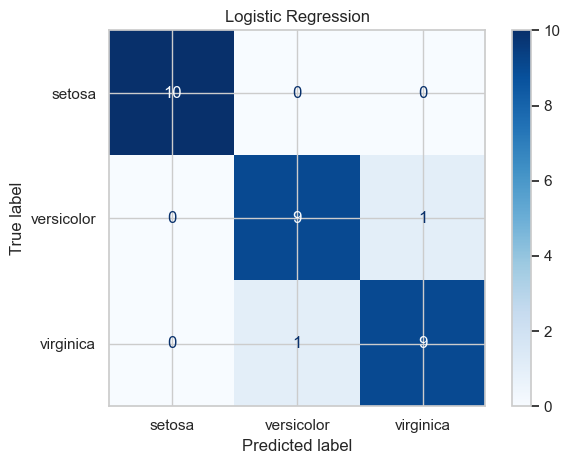


=== K-Nearest Neighbours ===
Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



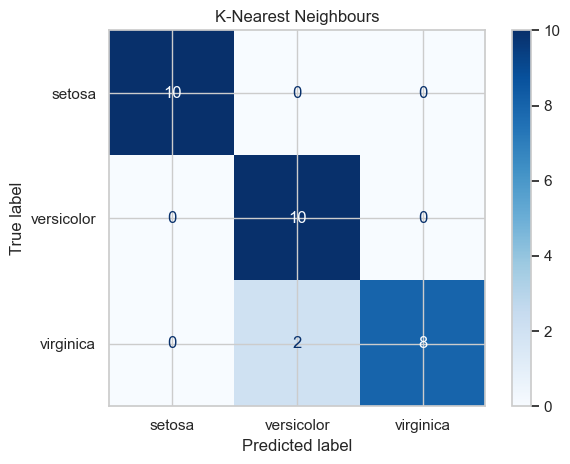


=== Random Forest ===
Accuracy: 0.9
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



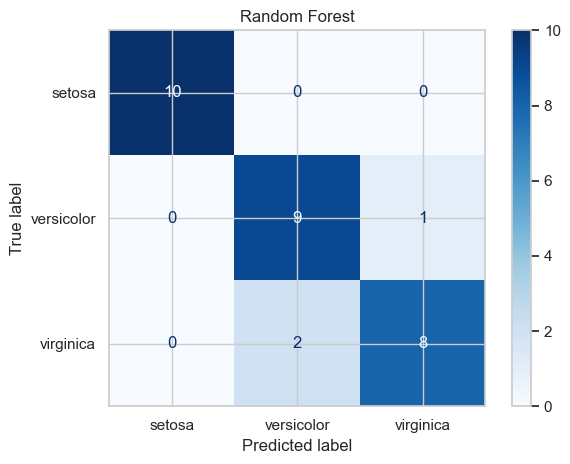

In [7]:
for name,model in fitted.items():
 pred=model.predict(X_test); print('\n===',name,'==='); print('Accuracy:',accuracy_score(y_test,pred)); print(classification_report(y_test,pred,zero_division=0))
 ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=iris.target_names,cmap='Blues'); plt.title(name); plt.tight_layout(); plt.show()

## 6. Best model and feature importance

Select by highest macro F1, using accuracy as tie-breaker. If scores tie, report that the models are effectively tied rather than claiming a large advantage. Macro F1 weights all three species equally.

Selected: Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



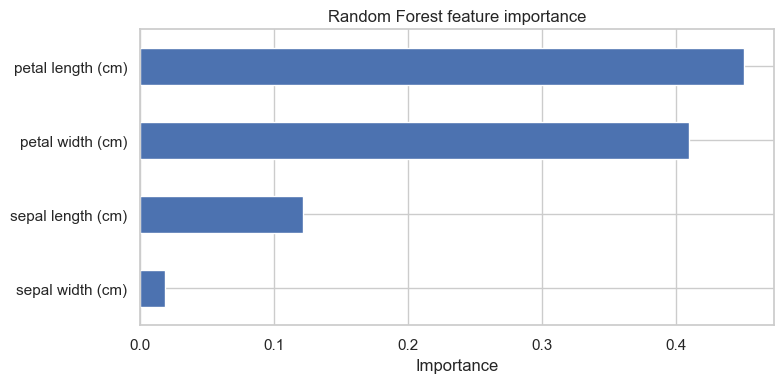

In [8]:
best_name=results.iloc[0]['Model']; best_model=fitted[best_name]; pred=best_model.predict(X_test)
print('Selected:',best_name); print(classification_report(y_test,pred,zero_division=0))
importance=pd.Series(fitted['Random Forest'].feature_importances_,index=features).sort_values()
importance.plot(kind='barh',figsize=(8,4),title='Random Forest feature importance'); plt.xlabel('Importance'); plt.tight_layout(); plt.show()

## 7. Try a new flower

In [9]:
# Order: sepal length, sepal width, petal length, petal width (cm)
new_flower=pd.DataFrame([[5.1,3.5,1.4,.2]],columns=features)
print('Predicted species:',best_model.predict(new_flower)[0])

Predicted species: setosa


## 8. Conclusion and limitations

The workflow includes data inspection, EDA, stratified splitting, model comparison, and evaluation. Petal measurements are typically the strongest separators. Report the measured test accuracy, macro F1, and confusion matrix. Iris is a small, clean teaching dataset; performance may not generalize to different measurement conditions.